In [ ]:
# Compute dot product
result = torch.dot(a, b)

In [ ]:
# Transpose it to 3 rows, 2 columns
x_transposed = x.T  # or torch.t(x)


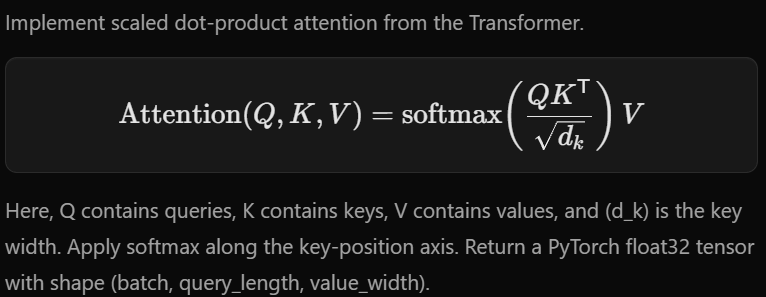

In [1]:
from PIL import Image
img = Image.open(r"C:\Users\Sagar\Downloads\attention.png")
img

In [2]:
import torch
import torch.nn.functional as F
import math

def scaled_dot_product_attention(Q: torch.Tensor, K: torch.Tensor, V: torch.Tensor) -> torch.Tensor:
    """
    Returns the scaled dot-product attention output.
    Assumes inputs are of shape (seq_len, d_k) or (batch_size, seq_len, d_k).
    """
    # 1. Get the dimension of the key vectors (d_k) from the last axis
    d_k = K.shape[-1]
    
    # 2. Compute QK^T using matrix multiplication (NOT torch.dot)
    # transpose(-2, -1) safely swaps the last two dimensions even if there is a batch dimension
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
    
    # 3. Apply Softmax along the very last dimension (dim=-1)
    attention_weights = F.softmax(scores, dim=-1)
    
    # 4. Multiply by V to get the final context vectors
    output = torch.matmul(attention_weights, V)
    
    return output
